## Fine-Tuning DistilBERT for Enterprise Query Classification

DistilBERT is a smaller, faster version of BERT trained through knowledge distillation.

It already understands many patterns in English text because it was pretrained on large text corpora.

However, it has not been specifically trained to classify our four enterprise query categories.

Fine-tuning adapts its learned representations to this new task.

### Install libraries

In [1]:
%pip install -q transformers datasets accelerate scikit-learn pandas


Note: you may need to restart the kernel to use updated packages.


*   transformers for DistilBERT and the Trainer.
*   datasets for preparing model-compatible datasets.
*   accelerate for training execution.
*   scikit-learn for evaluation.
*   pandas for CSV processing.

### Load the datasets

In [7]:
import pandas as pd

train_df = pd.read_csv("../data/training/train.csv")
val_df = pd.read_csv("../data/training/validation.csv")
test_df = pd.read_csv("../data/training/test.csv")

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nTraining class distribution:")
print(train_df["label"].value_counts().sort_index())

print("\nValidation class distribution:")
print(val_df["label"].value_counts().sort_index())

print("\nTest class distribution:")
print(test_df["label"].value_counts().sort_index())

train_groups = set(train_df["intent_group"])
val_groups = set(val_df["intent_group"])
test_groups = set(test_df["intent_group"])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

print("\nIntent-group separation: PASS")


Training: 240
Validation: 80
Testing: 80

Training class distribution:
label
0    60
1    60
2    60
3    60
Name: count, dtype: int64

Validation class distribution:
label
0    20
1    20
2    20
3    20
Name: count, dtype: int64

Test class distribution:
label
0    20
1    20
2    20
3    20
Name: count, dtype: int64

Intent-group separation: PASS


### Load the DistilBERT tokenizer
Transformers do not process raw strings directly. They operate on token IDs.

The tokenizer converts text into the numerical representation expected by the model.

In [8]:
#Tokenization
from transformers import AutoTokenizer

MODEL_NAME = "distilbert/distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

sample_text = "How do I apply for annual leave?"

encoded = tokenizer(
    sample_text,
    truncation=True,
    padding="max_length",
    max_length=128
)

print("Input IDs:", encoded["input_ids"][:20])
print("Attention mask:", encoded["attention_mask"][:20])


/workspaces/enterprise-knowledge-assistant/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Input IDs: [101, 2129, 2079, 1045, 6611, 2005, 3296, 2681, 1029, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Attention mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


Two important concepts:

Input IDs: Numerical representations of tokens.

Attention mask: Indicates which positions contain actual tokens and which are padding.

We use a maximum sequence length of 128 tokens because our employee queries are short.

### Convert CSV data into Hugging Face datasets

In [9]:
#Dataset preparation

from datasets import Dataset

train_dataset = Dataset.from_pandas(
    train_df[["text", "label"]],
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_df[["text", "label"]],
    preserve_index=False
)

test_dataset = Dataset.from_pandas(
    test_df[["text", "label"]],
    preserve_index=False
)

def tokenize_function(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=128
    )

train_dataset = train_dataset.map(
    tokenize_function,
    batched=True
)

val_dataset = val_dataset.map(
    tokenize_function,
    batched=True
)

test_dataset = test_dataset.map(
    tokenize_function,
    batched=True
)

print(train_dataset[0])


Map: 100%|██████████| 80/80 [00:00<00:00, 11842.46 examples/s]

{'text': 'Is manager approval required before taking leave?', 'label': 0, 'input_ids': [101, 2003, 3208, 6226, 3223, 2077, 2635, 2681, 1029, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


We're using dynamic padding later rather than padding every example to exactly 128 tokens. This can reduce unnecessary computation.

### Load DistilBERT for classification

In [10]:
#Model initialization

from transformers import AutoModelForSequenceClassification

id2label = {
    0: "HR & Leave",
    1: "IT Support",
    2: "Finance & Expenses",
    3: "Travel & Operations"
}

label2id = {
    name: index
    for index, name in id2label.items()
}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=4,
    id2label=id2label,
    label2id=label2id
)

print("Model loaded successfully.")


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 4617.90it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully.


Bad pipe message: %s [b'0.9,image/jxl,image/avif,image/webp,image/apng,*/*;q=0.8,application/signed-exchange;v=b3;q=0.7\r\nHost: localhost', b'4059\r\nUser-Agent: Mozilla/5.0 (Windows NT 10.0; Win64; x6', b' AppleWebKit/537.36 (KHTML, like Gecko) Chrome/156.', b'0.0 Safari/537.36\r\nAccept-Encoding: gzip, defla']
Bad pipe message: %s [b', br, zstd\r\nAccept-Language: en-US,en;q=0.9\r\nCache-Control: max-age=0\r\nReferer: https://github.com/\r\nX-Request-ID: ', b'c2e138459d2efc31e2c59273bf5f62\r\nX-Real-IP: 165.225.124', b'61\r\nX-Forwarded-Port: 443\r\nX-Forwarded-Scheme', b'https\r\nX-Original-URI: /\r\nX-Scheme: https\r\npriority: u=0,']
Bad pipe message: %s [b'\r\nsec-ch-ua: "Not:A-Brand";v="8', b' "Chromium";v="156", "Google Chro']


### Define evaluation metrics

We'll measure accuracy and macro F1-score.

Accuracy is the proportion of correctly classified examples.

Macro F1 calculates the F1-score for each category and averages them equally.

In [11]:
#Metrics
import numpy as np

from sklearn.metrics import accuracy_score, f1_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1_macro": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    }


### Configure fine-tuning

In [12]:
from transformers import (
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

training_args = TrainingArguments(
    output_dir="./eka-distilbert-results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=3,
    weight_decay=0.01,
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    report_to="none",
    seed=42,
    data_seed=42
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)



| Parameter | Value | Reason |
| :--- | :--- | :--- |
| **Learning rate** | 2e-5 | Conservative update rate for pretrained weights |
| **Batch size** | 8 | Suitable starting point for limited compute |
| **Epochs** | 3 | Initial experiment |
| **Weight decay** | 0.01 | Regularization |
| **Maximum length** | 128 | Short employee queries |
| **Selection metric** | Macro F1 | Equal importance to all categories |

These are initial values. We'll use validation results to determine whether changes are justified.

In [13]:
#Train the model

train_result = trainer.train()

print("Fine-tuning completed.")
print(train_result.metrics)


/workspaces/enterprise-knowledge-assistant/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.299817,1.257771,0.562500,0.537234
2,0.953571,0.969432,0.862500,0.862519
3,0.744234,0.833920,0.900000,0.900281


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.90it/s]
/workspaces/enterprise-knowledge-assistant/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.13it/s]
/workspaces/enterprise-knowledge-assistant/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.27it/s]


Fine-tuning completed.
{'train_runtime': 108.5689, 'train_samples_per_second': 6.632, 'train_steps_per_second': 0.829, 'total_flos': 3096535884288.0, 'train_loss': 1.076876735687256, 'epoch': 3.0}


This is the step where actual fine-tuning happens.

The optimizer updates the model's parameters using the training data.

Training duration depends on the available CPU or GPU and the dataset size.

### Evaluate on the test set

In [14]:
#Final evaluation

test_results = trainer.evaluate(
    eval_dataset=test_dataset
)

print("Test results:")
print(test_results)


/workspaces/enterprise-knowledge-assistant/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.744234,0.877529,3,0.787500,0.783432


Test results:
{'eval_loss': 0.8775293231010437, 'eval_accuracy': 0.7875, 'eval_f1_macro': 0.7834317642680012}


In [16]:
pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 19.1 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 17.4 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 12.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [matplotlib]6 [matplotlib]
Note: you may need to restart the kernel to use updated packages.


/workspaces/enterprise-knowledge-assistant/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


                     precision    recall  f1-score   support

         HR & Leave       0.82      0.70      0.76        20
         IT Support       0.95      1.00      0.98        20
 Finance & Expenses       0.62      0.90      0.73        20
Travel & Operations       0.85      0.55      0.67        20

           accuracy                           0.79        80
          macro avg       0.81      0.79      0.78        80
       weighted avg       0.81      0.79      0.78        80



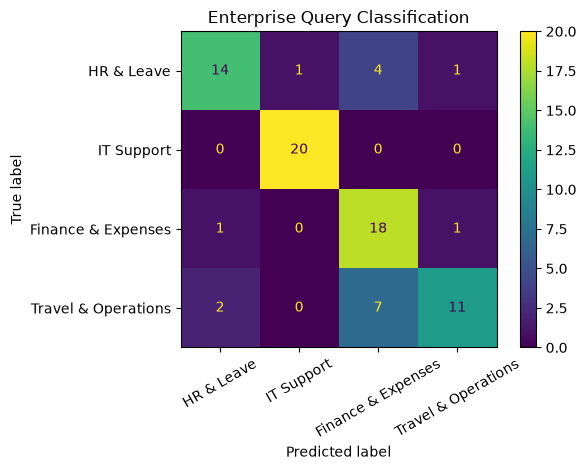

In [17]:
#Classification report and confusion matrix

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

pred_output = trainer.predict(test_dataset)

predictions = np.argmax(
    pred_output.predictions,
    axis=-1
)

true_labels = pred_output.label_ids

print(
    classification_report(
        true_labels,
        predictions,
        labels=[0, 1, 2, 3],
        target_names=list(id2label.values()),
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    true_labels,
    predictions,
    labels=[0, 1, 2, 3],
    display_labels=list(id2label.values()),
    xticks_rotation=30
)

plt.title("Enterprise Query Classification")
plt.tight_layout()
plt.show()

The confusion matrix will show which categories the model predicts correctly and which categories it confuses.

### Test with new employee questions

In [18]:
#Inference

import torch

def classify_query(text):
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=128
    )

    device = next(model.parameters()).device

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    model.eval()

    with torch.no_grad():
        outputs = model(**inputs)

    probabilities = torch.softmax(
        outputs.logits,
        dim=-1
    )[0]

    predicted_id = int(
        torch.argmax(probabilities).item()
    )

    return {
        "query": text,
        "category": id2label[predicted_id],
        "confidence": round(
            float(probabilities[predicted_id].item()),
            4
        )
    }


queries = [
    "I need permission to take two days off.",
    "My office VPN disconnects repeatedly.",
    "How can I get my business meal reimbursed?",
    "Where should I book my official flight?"
]

for query in queries:
    print(classify_query(query))


{'query': 'I need permission to take two days off.', 'category': 'HR & Leave', 'confidence': 0.4086}
{'query': 'My office VPN disconnects repeatedly.', 'category': 'IT Support', 'confidence': 0.5318}
{'query': 'How can I get my business meal reimbursed?', 'category': 'Finance & Expenses', 'confidence': 0.5839}
{'query': 'Where should I book my official flight?', 'category': 'Travel & Operations', 'confidence': 0.4734}


The output should contain a predicted category and confidence value for each query. The exact predictions and confidence values will depend on your training results.

Note that softmax confidence is not necessarily a calibrated probability of correctness.

### Save the fine-tuned model

In [19]:
#Export

from pathlib import Path
import shutil

MODEL_DIR = Path("eka-distilbert-model")

trainer.save_model(str(MODEL_DIR))
tokenizer.save_pretrained(str(MODEL_DIR))

archive_path = shutil.make_archive(
    "eka-distilbert-model",
    "zip",
    root_dir=".",
    base_dir=str(MODEL_DIR)
)

print("Model archive:", archive_path)


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.83it/s]


Model archive: /workspaces/enterprise-knowledge-assistant/notebook/eka-distilbert-model.zip
